# 03 · Исправленные классификаторы и сигнальные ориентиры

## tl;dr

Новые CatBoost, сплайны и линейные модели работают без quality/duration, дублирующих единиц и missing indicators. Четыре профиля, полные обязательные поля, 5×3 grouped nested CV. Для single/ensemble выделена отдельная mode-группа, для калибровки — другая. Сигнальные ориентиры используют те же внешние группы.

| Профиль | Macro-F1 на принятых | Recall abnormal | Охват JNU |
|---|---:|---:|---:|
| core3 | 0.673 | 63.8% | 99.87% |
| report4s5 | 0.720 | 70.8% | 99.79% |
| report5 | 0.722 | 70.7% | 99.79% |
| report7 | 0.732 | 72.1% | 99.79% |

Охват JNU относится к полноте собственных измерений; он не означает такой же охват больничных отчётов с неизвестными определениями.


## Context & Methods
### Key Assumptions
Новая версия использует все уже известные данные JNU для exploratory nested CV. Каждая внешняя fit-часть делится по patient_component: 80% proper-fit /20% calibration; proper-fit отдельно делится на tune/mode-holdout. Сетка видит только tune; single/ensemble оцениваются на mode-holdout; реальный агрегатор fit на proper-fit и sigmoid-калибруется на calibration. Внешние метки ни на один выбор не влияют. Одна единица на величину, без missing indicators/imputation в report-моделях.


In [3]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'pyproject.toml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
REVIEW=ROOT/'research/reviews/ctg_20261017'
UCI=ROOT/'research/experiments/ctg_uci/reviewed_v3'
JNU=ROOT/'research/experiments/jnu_ctg/reviewed_v2'
FIGURES=REVIEW/'figures';FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',170)
sns.set_theme(style='whitegrid',font_scale=1.0)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False})
COLORS={'linear':'#009e73','spline':'#d55e00','catboost':'#0072b2'}
def save_show(name):
    plt.gcf().savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    plt.show()


## Data · запуск и полный протокол

In [5]:
from src.training.jnu_review_experiment import run
metrics=run()
protocol=json.loads((JNU/'protocol.json').read_text())
display(pd.Series({k:v for k,v in protocol.items() if k not in ['input_sha256','grids']}).to_frame('protocol'))
display(metrics.round(4))


,protocol
fingerprint,8179542f26c41f776758e163dbf970126cfbc607c4f6f3e4bed72a7b3a36693e
environment,"{'numpy': '2.4.6', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'catboost': '1.2.10'}"
profiles,"{'core3': ['baseline_bpm', 'acc15_per_10min', 'dec15_per_10min'], 'report5': ['baseline_bpm', 'acc15_per_10min', 'dec15_per_10min', 'stv_ms', 'amplitude_bpm'], 'repor..."
outer_folds,5
inner_folds,3
eligibility,complete required profile measurements; coverage over every source row
missingness,no imputation or indicators in report models; missing/unconfirmed required fields abstain before inference
removed_inputs,"[signal_loss_pct, duration_min, duplicate variability units, unverified episode rules]"
selector,one-SE group-log-loss parsimony heuristic
mode_selection,separate grouped 20% mode holdout excluded from grid; compare chosen params at identical holdout


,profile,family,coverage,abstained,group_macro_f1,group_recall,group_specificity,group_precision,group_log_loss,group_ap,group_auc,group_brier,records,groups
0,core3,catboost,0.9987,26,0.6763,0.6199,0.7434,0.7419,0.5908,0.7872,0.7366,0.2043,20743,12590
1,core3,linear,0.9987,26,0.6700,0.6299,0.7179,0.7265,0.5975,0.7824,0.7304,0.2069,20743,12590
2,core3,selected_procedure,0.9987,26,0.6731,0.6381,0.7149,0.7270,0.5922,0.7861,0.7347,0.2048,20743,12590
3,core3,spline,0.9987,26,0.6728,0.6459,0.7054,0.7228,0.5918,0.7862,0.7355,0.2046,20743,12590
4,report4s5,catboost,0.9979,43,0.7208,0.7084,0.7370,0.7618,0.5370,0.8372,0.7993,0.1816,20726,12582
5,report4s5,linear,0.9979,43,0.7119,0.6957,0.7322,0.7553,0.5516,0.8262,0.7851,0.1875,20726,12582
6,report4s5,selected_procedure,0.9979,43,0.7204,0.7081,0.7363,0.7613,0.5386,0.8354,0.7982,0.1821,20726,12582
7,report4s5,spline,0.9979,43,0.7198,0.7058,0.7378,0.7617,0.5396,0.8347,0.7970,0.1826,20726,12582
8,report5,catboost,0.9979,43,0.7224,0.7074,0.7413,0.7646,0.5377,0.8366,0.7987,0.1819,20726,12582
9,report5,linear,0.9979,43,0.7118,0.6946,0.7332,0.7557,0.5517,0.8262,0.7849,0.1875,20726,12582


## Results · компактные профили и семейства

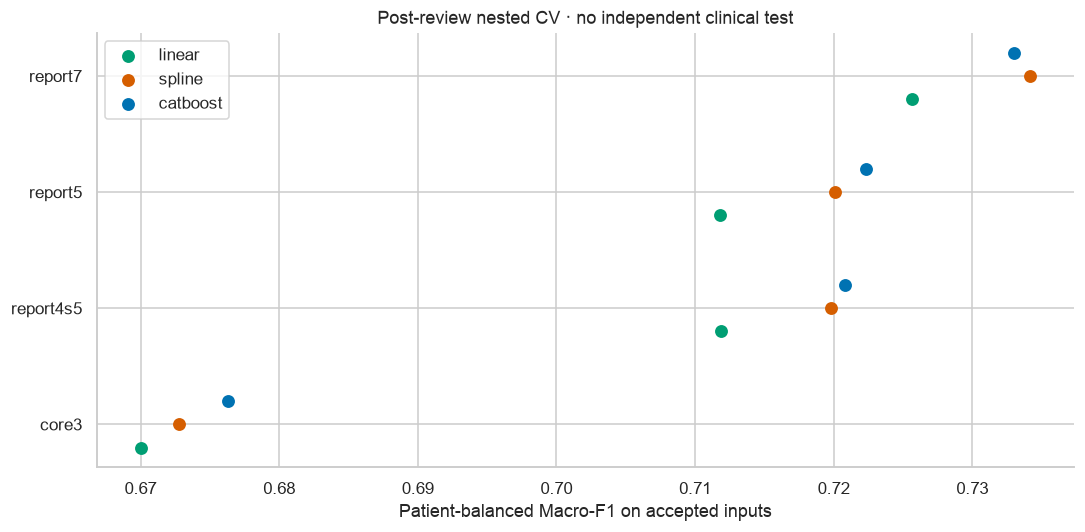

outer_fits
profile   family   mode              
core3     catboost single           5
          linear   single           5
          spline   single           5
report4s5 catboost single           5
          linear   single           5
          spline   single           5
report5   catboost single           5
          linear   single           5
          spline   single           5
report7   catboost single           5
          linear   single           5
          spline   single           5

,label,profile,family,mode,inner_loss,selected_family
0,outer0,core3,linear,single,0.597180,spline
1,outer0,core3,spline,single,0.591505,spline
2,outer0,core3,catboost,single,0.592530,spline
3,outer0,report5,linear,single,0.550184,spline
4,outer0,report5,spline,single,0.539669,spline
5,outer0,report5,catboost,single,0.539822,spline
6,outer0,report7,linear,single,0.526640,spline
7,outer0,report7,spline,single,0.517850,spline
8,outer0,report7,catboost,single,0.521163,spline
9,outer0,report4s5,linear,single,0.549950,spline


In [7]:
fig,ax=plt.subplots(figsize=(10,5))
profiles=list(metrics.profile.unique())
for family,offset in [('linear',-.2),('spline',0),('catboost',.2)]:
    z=metrics[metrics.family==family].set_index('profile').loc[profiles]
    ax.scatter(z.group_macro_f1,np.arange(len(z))+offset,label=family,color=COLORS[family],s=55)
ax.set(yticks=range(len(profiles)),yticklabels=profiles,xlabel='Patient-balanced Macro-F1 on accepted inputs',title='Post-review nested CV · no independent clinical test')
ax.legend();fig.tight_layout();save_show('jnu03_profile_comparison.png')
choices=pd.read_json(JNU/'choices.json')
display(choices.groupby(['profile','family','mode']).size().rename('outer_fits').to_frame())
display(choices[['label','profile','family','mode','inner_loss','selected_family']].head(18))


### Сигнальные ориентиры на одинаковых фолдах

raw_minute210 — 210 временных дескрипторов двух сырых каналов, не end-to-end нейросеть. F_* остаются quarantined reference.


,representation,records,groups,group_macro_f1,group_auc,group_ap
0,fhr_std_only,20726,12582,0.7439,0.8172,0.8593
1,published_F_quarantined,20726,12582,0.8952,0.9644,0.9710
2,quality_only,20726,12582,0.6222,0.6495,0.6547
3,raw_minute210,20726,12582,0.7771,0.8607,0.8906
4,report5,20726,12582,0.7217,0.7984,0.8369
5,report5_plus_quality,20726,12582,0.7345,0.8178,0.8480
6,signal27,20726,12582,0.7906,0.8719,0.9011


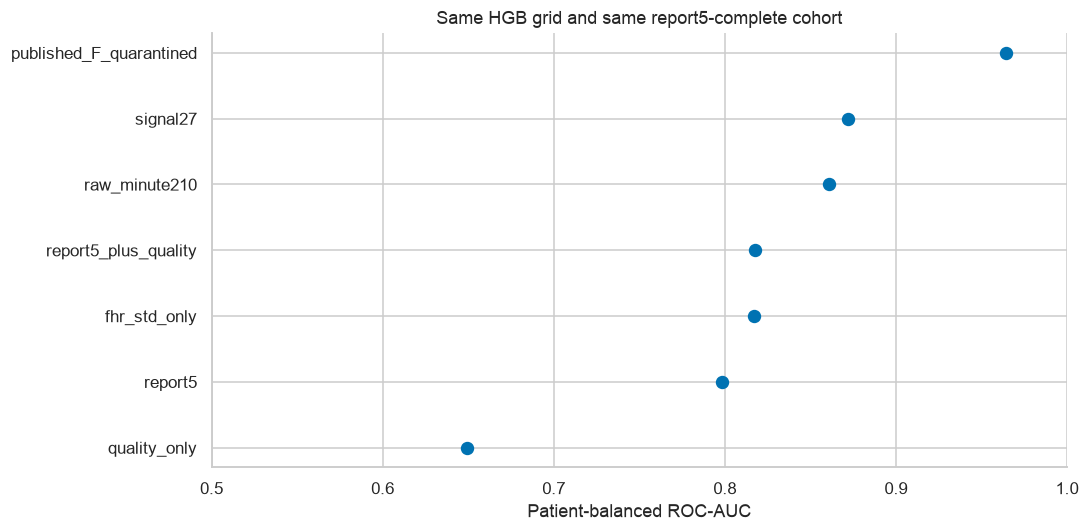

In [9]:
reference=pd.read_csv(JNU/'representation_metrics.csv')
display(reference[['representation','records','groups','group_macro_f1','group_auc','group_ap']].round(4))
fig,ax=plt.subplots(figsize=(10,5));z=reference.sort_values('group_auc')
ax.scatter(z.group_auc,np.arange(len(z)),s=60,color='#0072b2');ax.set(yticks=range(len(z)),yticklabels=z.representation,xlabel='Patient-balanced ROC-AUC',xlim=(.5,1),title='Same HGB grid and same report5-complete cohort')
fig.tight_layout();save_show('jnu03_representation_benchmark.png')
print('raw_minute210 — 210 временных дескрипторов двух сырых каналов, не end-to-end нейросеть. F_* остаются quarantined reference.')


### Экспорт и честное сравнение усреднения

In [11]:
final=pd.read_json(JNU/'final_choices.json')
display(final[['profile','family','params','mode','selected_family','proper_fit_records','calibration_records']])
print('Финальные mode counts:',final['mode'].value_counts().to_dict())
print('Все bundles, native CatBoost и отдельные scalers/bases сохранены в models/exported/jnu_ctg/reviewed_v2.')
print('Выбор modes относится к данным параметрам и критерию, не ко всем возможным ансамблям.')


Финальные mode counts: {'single': 11, 'ensemble5': 1}
Все bundles, native CatBoost и отдельные scalers/bases сохранены в models/exported/jnu_ctg/reviewed_v2.
Выбор modes относится к данным параметрам и критерию, не ко всем возможным ансамблям.


,profile,family,params,mode,selected_family,proper_fit_records,calibration_records
0,core3,linear,{'C': 0.1},single,spline,16593,4150
1,core3,spline,"{'C': 3.0, 'n_knots': 3}",single,spline,16593,4150
2,core3,catboost,"{'auto_class_weights': None, 'depth': 3, 'iterations': 300, 'l2_leaf_reg': 10, 'learning_rate': 0.05}",single,spline,16593,4150
3,report5,linear,{'C': 0.1},single,spline,16580,4146
4,report5,spline,"{'C': 30.0, 'n_knots': 3}",single,spline,16580,4146
5,report5,catboost,"{'auto_class_weights': None, 'depth': 3, 'iterations': 300, 'l2_leaf_reg': 10, 'learning_rate': 0.05}",single,spline,16580,4146
6,report7,linear,{'C': 1.0},single,spline,16580,4146
7,report7,spline,"{'C': 30.0, 'n_knots': 3}",single,spline,16580,4146
8,report7,catboost,"{'auto_class_weights': None, 'depth': 3, 'iterations': 700, 'l2_leaf_reg': 3, 'learning_rate': 0.05}",ensemble5,spline,16580,4146
9,report4s5,linear,{'C': 0.1},single,spline,16580,4146


## Takeaways

Цель — морфологическая метка normal/abnormal JNU. Она не заменяет клинический исход или полные критерии Доуза–Редмана. Совместимость с российским прибором не подтверждена; общий вход приложения возвращает отказ до модели. Сырые сигналы нужны только для исследования измерений, не обязательны для будущего приложения.
